## 6. Regular Season EDA

In this section, we conduct a detailed Exploratory Data Analysis (EDA) on the cleaned regular-season dataset (`df_regular_clean`). As required, we create a copy of the clean dataset named `eda` to protect our original variables, use an `eda_` prefix for new helper variables, and filter out any rows where `suspicious_entry == True` for correlations and trend analyses.

### 6A. Distributions of the performance stats

We want to inspect how individual performance statistics (such as points, rebounds, assists, blocks, steals, minutes, games played, true shooting percentage, and plus/minus) are distributed across all player-seasons. This helps us understand if the stats are symmetric or skewed, which is highly important for statistical modeling.

(5254, 25)


,Mean,Median,Std Dev,Skewness
ppg,9.358,7.710,6.301,1.110
rpg,3.788,3.280,2.393,1.362
apg,2.103,1.480,1.835,1.693
bpg,0.421,0.300,0.404,2.327
spg,0.668,0.610,0.396,0.876
mpg,20.773,20.465,8.795,-0.036
gp,52.885,57.000,20.768,-0.491
ts_pct,0.553,0.556,0.069,-0.784
plus_minus,-0.254,-0.380,2.968,0.264


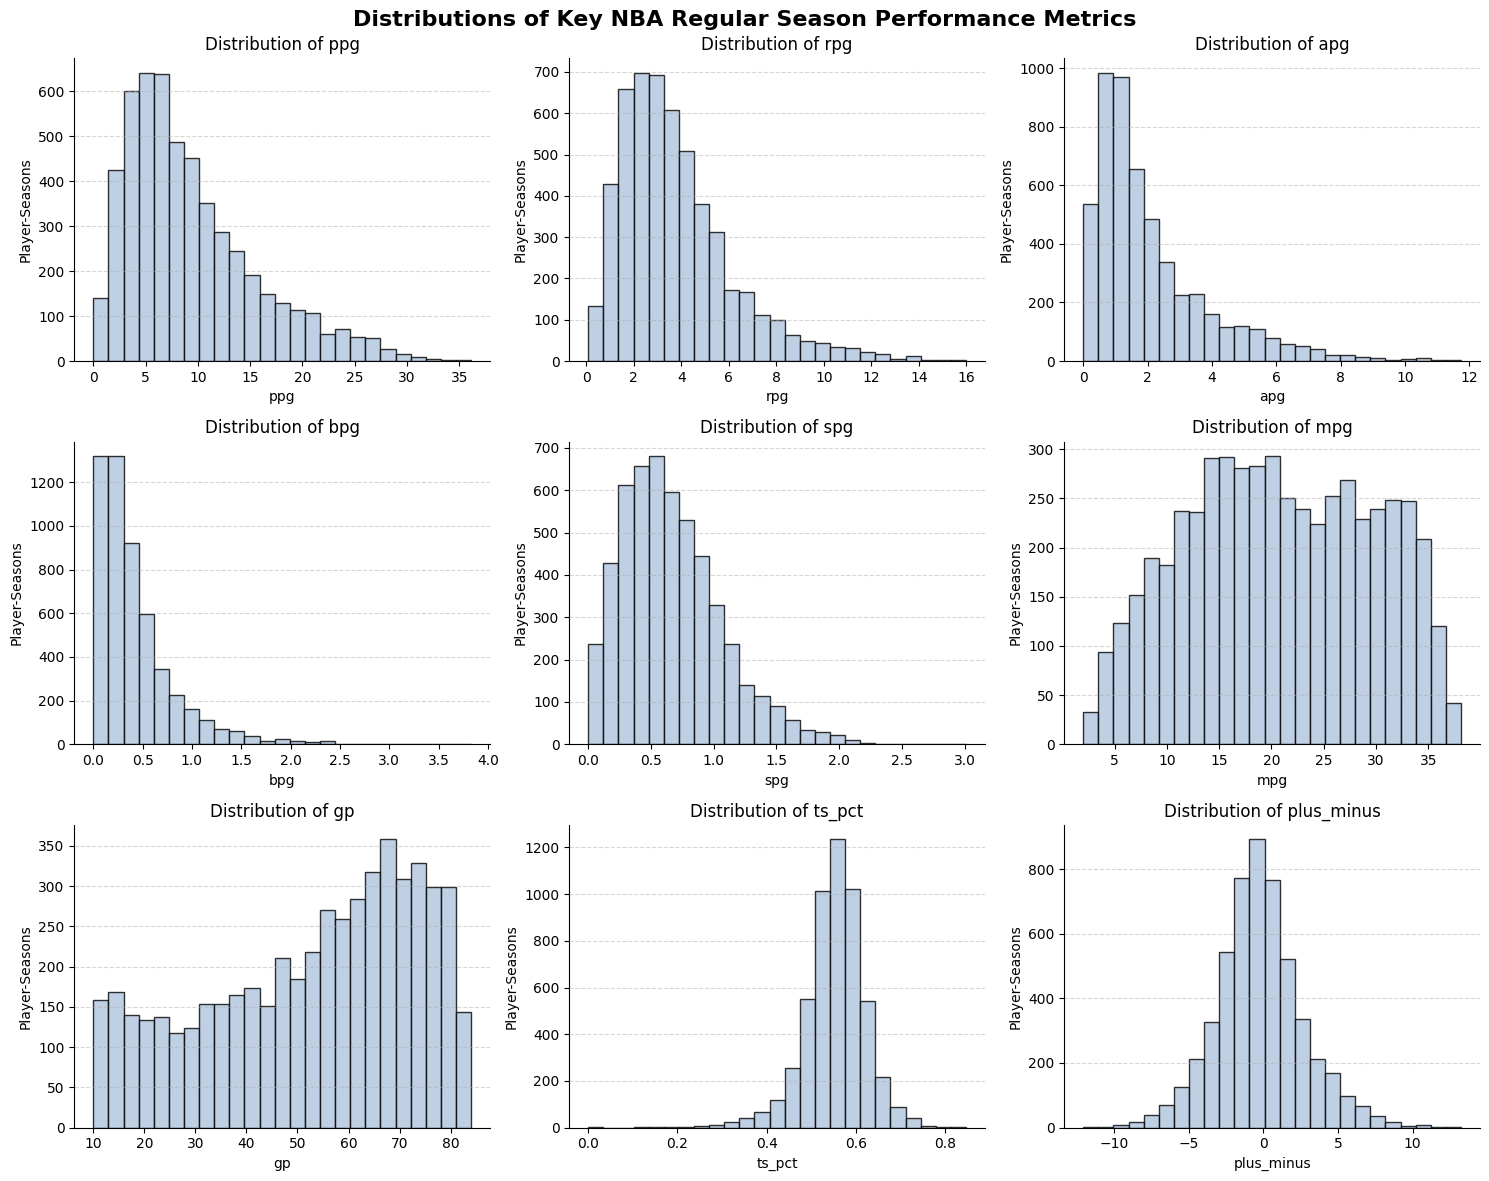

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_regular_clean = pd.read_csv('data/02-processed/nba_regular_season_cleaned.csv')
print(df_regular_clean.shape)

# Create the eda copy to avoid changing df_regular_clean
eda = df_regular_clean.copy()

# Stat columns to analyze
eda_stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus']

# Calculate descriptive statistics
eda_summary_table = pd.DataFrame({
    'Mean': eda[eda_stat_cols].mean(),
    'Median': eda[eda_stat_cols].median(),
    'Std Dev': eda[eda_stat_cols].std(),
    'Skewness': eda[eda_stat_cols].skew()
})
display(eda_summary_table.round(3))

# Plot a 3x3 grid of histograms
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(eda_stat_cols):
    axes[i].hist(eda[col], bins=25, color='lightsteelblue', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Player-Seasons')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Distributions of Key NBA Regular Season Performance Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found

* **Right-skewed stats:** `bpg` (skew 2.33), `apg` (1.69), `rpg` (1.36), `ppg` (1.11) and `spg` (0.88) are right-skewed. Most players have low numbers and a few stars have very high ones, so the mean is above the median (for example, `ppg` mean 9.4 vs median 7.7).
* **Close to symmetric:** `mpg` (skew -0.04) is almost symmetric. `gp` (-0.49) and `ts_pct` (-0.78) have a longer tail on the low side, from players who miss games or shoot badly in very few minutes.
* **Plus/minus:** `plus_minus` (skew 0.26) is roughly symmetric and centered slightly below zero (mean -0.25, median -0.38).

### 6B. Age and experience

We look at the age and years of experience of NBA players to see how long careers usually last and how playing time and scoring change as players grow older and more experienced.

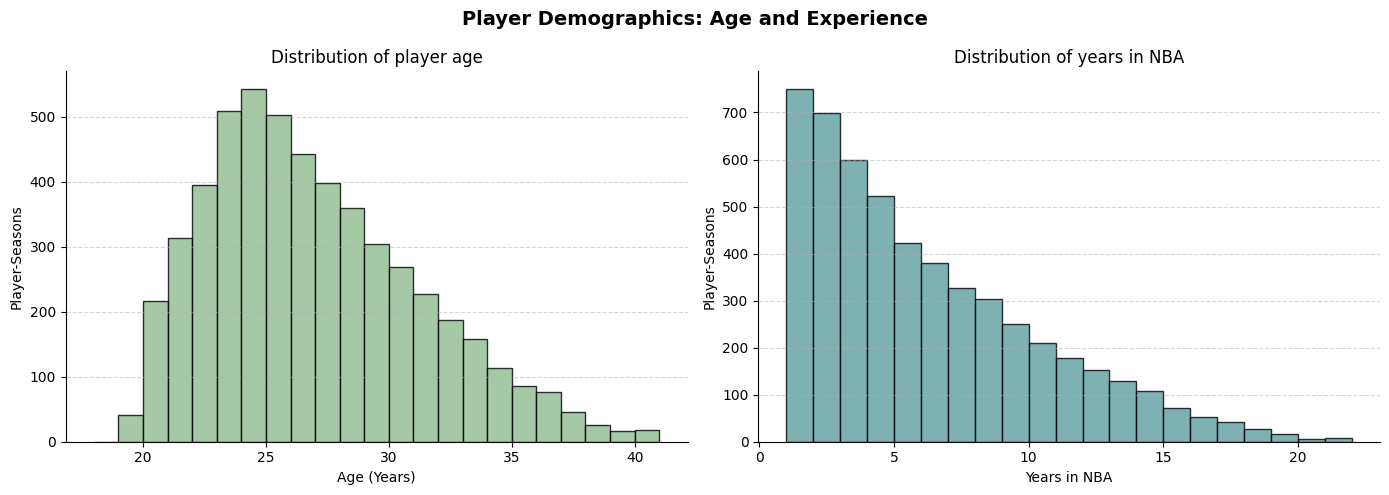

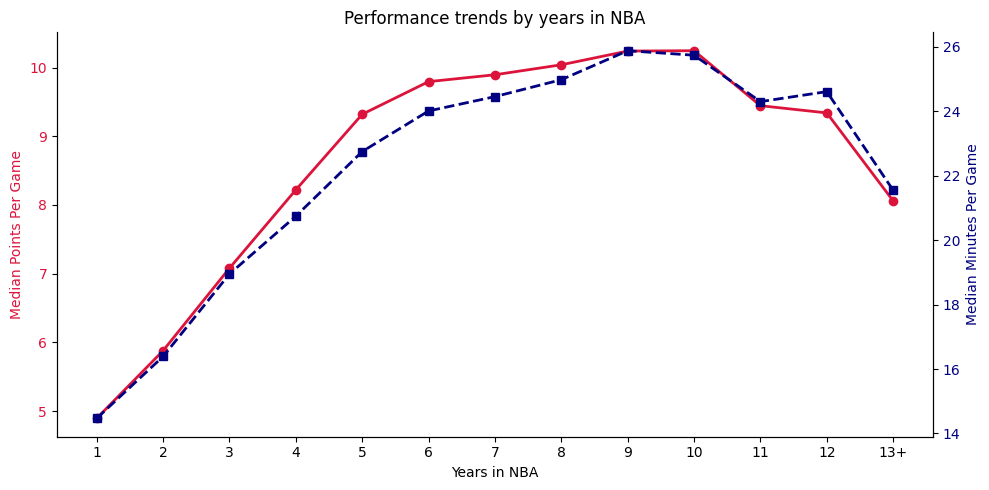

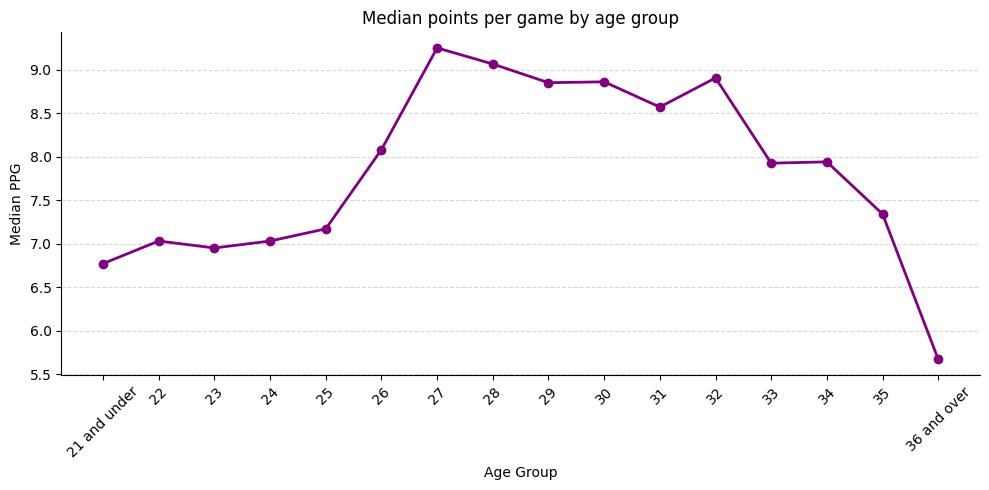

Share of rows with estimated years_in_nba: 19.0712%


In [5]:
# 1. Histograms of age and years_in_nba
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(eda['age'], bins=range(18, 42), color='darkseagreen', edgecolor='black', alpha=0.8)
axes[0].set_title('Distribution of player age')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Player-Seasons')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].yaxis.grid(True, linestyle='--', alpha=0.5)

axes[1].hist(eda['years_in_nba'], bins=range(1, 23), color='cadetblue', edgecolor='black', alpha=0.8)
axes[1].set_title('Distribution of years in NBA')
axes[1].set_xlabel('Years in NBA')
axes[1].set_ylabel('Player-Seasons')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Player Demographics: Age and Experience', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Line chart: median ppg and median mpg by years_in_nba (capped at 13+)
eda_exp = eda.copy()
eda_exp['exp_group'] = eda_exp['years_in_nba'].apply(lambda x: '13+' if x >= 13 else str(int(x)))

# Sort group keys properly
eda_exp_order = [str(i) for i in range(1, 13)] + ['13+']
eda_exp_grouped = eda_exp.groupby('exp_group')[['ppg', 'mpg']].median().reindex(eda_exp_order)

fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'crimson'
ax1.set_xlabel('Years in NBA')
ax1.set_ylabel('Median Points Per Game', color=color)
ax1.plot(eda_exp_grouped.index, eda_exp_grouped['ppg'], marker='o', color=color, linewidth=2, label='Median PPG')
ax1.tick_params(axis='y', labelcolor=color)
ax1.spines['top'].set_visible(False)

ax2 = ax1.twinx()
color = 'navy'
ax2.set_ylabel('Median Minutes Per Game', color=color)
ax2.plot(eda_exp_grouped.index, eda_exp_grouped['mpg'], marker='s', linestyle='--', color=color, linewidth=2, label='Median MPG')
ax2.tick_params(axis='y', labelcolor=color)
ax2.spines['top'].set_visible(False)

plt.title('Performance trends by years in NBA')
plt.tight_layout()
plt.show()

# 3. Line chart: median ppg by age (grouped <21 and >36 into end groups)
eda_age = eda.copy()
def age_group(a):
    if a <= 21:
        return '21 and under'
    elif a >= 36:
        return '36 and over'
    else:
        return str(int(a))

eda_age['age_group'] = eda_age['age'].apply(age_group)
eda_age_order = ['21 and under'] + [str(i) for i in range(22, 36)] + ['36 and over']
eda_age_grouped = eda_age.groupby('age_group')['ppg'].median().reindex(eda_age_order)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(eda_age_grouped.index, eda_age_grouped.values, marker='o', color='purple', linewidth=2)
ax.set_title('Median points per game by age group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Median PPG')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Share of rows with estimated years_in_nba
estimated_share = eda['years_in_nba_estimated'].mean()
print(f"Share of rows with estimated years_in_nba: {estimated_share:.4%}")

### What we found

* **Young league:** The middle half of player-seasons are between 23 and 29 years old (median 26). The most common value of `years_in_nba` is 1, and the median is 5.
* **Experience:** Median `ppg` rises from 4.9 in the first year to 10.2 in years 9 and 10, then falls to 8.1 for 13+ years. Median `mpg` follows the same shape (14.5 in year 1, 25.9 in year 9, 21.6 for 13+). Part of this rise is survivor bias, because weaker players leave the league early.
* **Age:** Median `ppg` is about 7 for ages 21-25, rises to 8.1 at 26 and 9.3 at 27, stays around 8-9 into the early 30s, and drops to 5.7 for 36 and over.
* **Estimated years:** 19.1% of rows have `years_in_nba_estimated == True` (no draft year, so the value is estimated from the player's first season in the data). This is a large share, so `years_in_nba` should be used with care. It can be too small for undrafted players who started before our first season.

### 6C. Playing time

Minutes per game represents a player's opportunity on the court. We analyze how playing time affects scoring volume, shooting efficiency, and plus/minus, and isolate scoring outliers.

,count,median_ppg,median_ts_pct,median_plus_minus
mpg_bin,,,,
0-10,683,2.30,0.518,-0.61
10-20,1847,5.42,0.545,-0.77
20-30,1719,10.13,0.562,-0.35
30+,1005,18.59,0.573,1.64


Correlation between mpg and ppg (excluding 3 suspicious rows): 0.8752


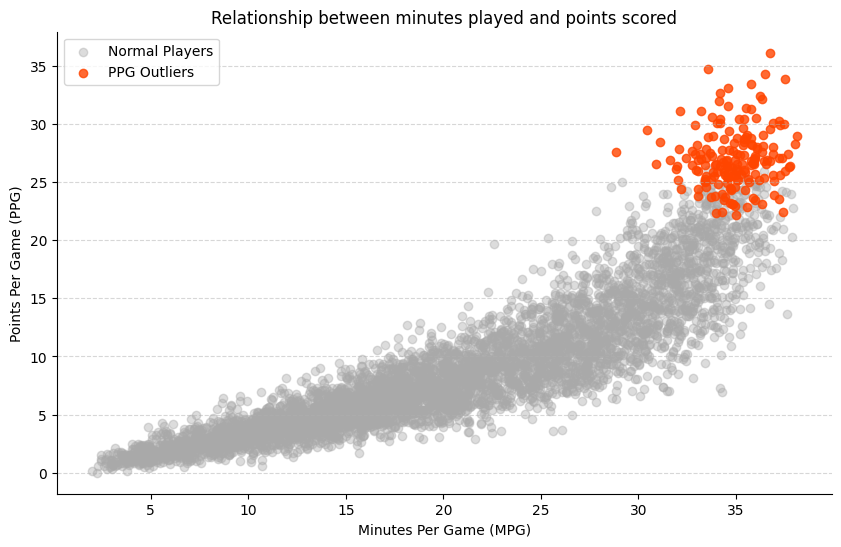

In [6]:
# Bin minutes per game
def bin_mpg(m):
    if m < 10:
        return '0-10'
    elif m < 20:
        return '10-20'
    elif m < 30:
        return '20-30'
    else:
        return '30+'

eda['mpg_bin'] = eda['mpg'].apply(bin_mpg)
eda_mpg_grouped = eda.groupby('mpg_bin').agg(
    count=('ppg', 'count'),
    median_ppg=('ppg', 'median'),
    median_ts_pct=('ts_pct', 'median'),
    median_plus_minus=('plus_minus', 'median')
).reindex(['0-10', '10-20', '20-30', '30+'])

display(eda_mpg_grouped)

# Calculate correlation between mpg and ppg (excluding suspicious entries)
eda_no_susp = eda[eda['suspicious_entry'] == False]
eda_corr_mpg_ppg = eda_no_susp['mpg'].corr(eda_no_susp['ppg'])
print(f"Correlation between mpg and ppg (excluding {eda['suspicious_entry'].sum()} suspicious rows): {eda_corr_mpg_ppg:.4f}")

# Scatter plot of mpg vs ppg highlighting outliers
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(eda[eda['ppg_outlier'] == False]['mpg'], eda[eda['ppg_outlier'] == False]['ppg'],
           alpha=0.4, color='darkgray', label='Normal Players')
ax.scatter(eda[eda['ppg_outlier'] == True]['mpg'], eda[eda['ppg_outlier'] == True]['ppg'],
           alpha=0.8, color='orangered', label='PPG Outliers')
ax.set_title('Relationship between minutes played and points scored')
ax.set_xlabel('Minutes Per Game (MPG)')
ax.set_ylabel('Points Per Game (PPG)')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strong link between minutes and points:** The correlation between `mpg` and `ppg` is 0.875 (without the 3 suspicious rows).
* **Bigger roles look better:** From the 0-10 minute group to the 30+ group, median `ppg` goes from 2.3 to 18.6 and median `ts_pct` from 51.8% to 57.3%. Median `plus_minus` is slightly negative for the first three groups (-0.61, -0.77, -0.35) and positive only for 30+ minutes (+1.64).
* **Scoring outliers:** All 176 scoring outliers play at least 28.9 minutes per game, so scoring far above the season's typical level requires a starter's minutes.

### 6D. Relationships between variables

We calculate linear correlations between all major performance statistics, player age, and experience to identify collinearity and see how scoring connects to general impact.

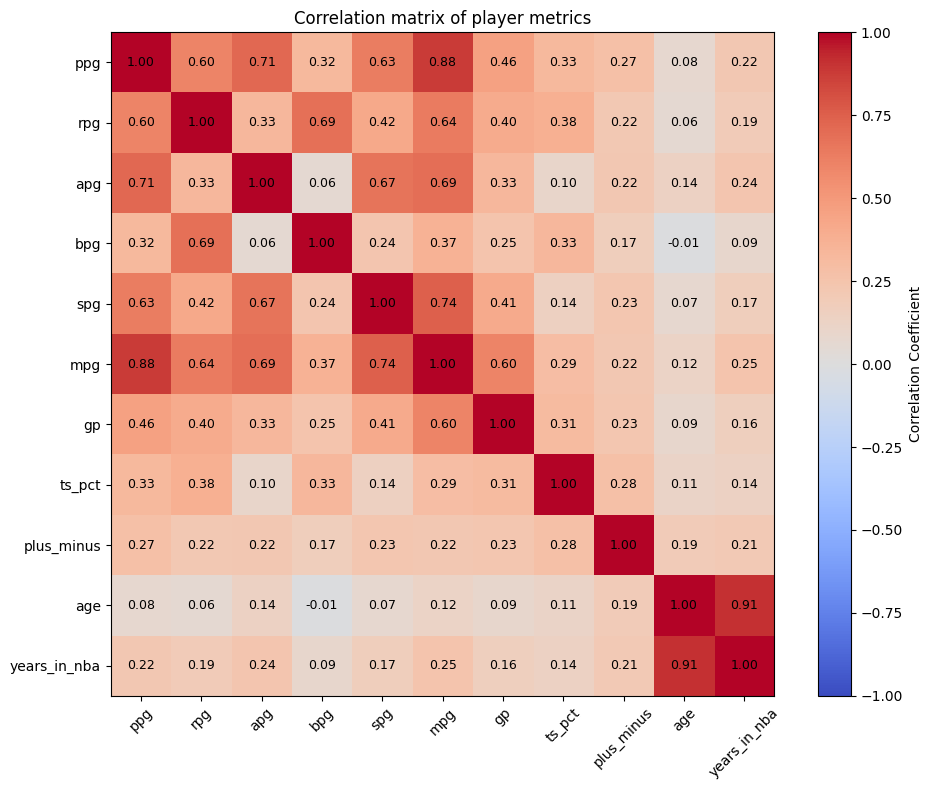


--- Top 5 Strongest Correlation Pairs ---
years_in_nba & age: 0.9075
ppg & mpg: 0.8752
mpg & spg: 0.7427
apg & ppg: 0.7139
apg & mpg: 0.6905


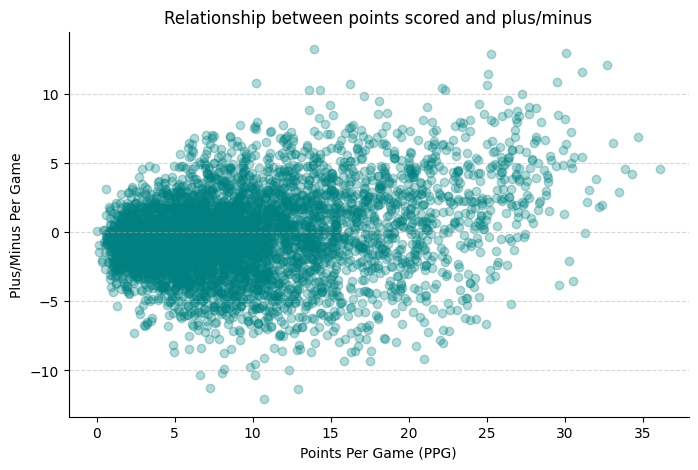

In [7]:
# Columns to include in heatmap
eda_corr_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'age', 'years_in_nba']

# Compute correlation matrix on rows without suspicious entries
eda_corr_matrix = eda_no_susp[eda_corr_cols].corr()

# Plot heatmap with matplotlib imshow
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(eda_corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)

# Add values inside cells
for i in range(len(eda_corr_cols)):
    for j in range(len(eda_corr_cols)):
        text = ax.text(j, i, f"{eda_corr_matrix.iloc[i, j]:.2f}",
                       ha="center", va="center", color="black", fontsize=9)

ax.set_xticks(range(len(eda_corr_cols)))
ax.set_yticks(range(len(eda_corr_cols)))
ax.set_xticklabels(eda_corr_cols, rotation=45)
ax.set_yticklabels(eda_corr_cols)
fig.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.title('Correlation matrix of player metrics')
plt.tight_layout()
plt.show()

# Find top 5 strongest pairs
eda_flat_corr = eda_corr_matrix.abs().unstack()
# Remove diagonal self-pairs
eda_flat_corr = eda_flat_corr[eda_flat_corr < 0.9999]
# Get unique values
eda_top_pairs = eda_flat_corr.sort_values(ascending=False).drop_duplicates().head(5)
print("\n--- Top 5 Strongest Correlation Pairs ---")
for idx, val in eda_top_pairs.items():
    # Get original signed value
    signed_val = eda_corr_matrix.loc[idx[0], idx[1]]
    print(f"{idx[0]} & {idx[1]}: {signed_val:.4f}")

# Scatter: ppg vs plus_minus
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(eda['ppg'], eda['plus_minus'], alpha=0.3, color='teal')
ax.set_title('Relationship between points scored and plus/minus')
ax.set_xlabel('Points Per Game (PPG)')
ax.set_ylabel('Plus/Minus Per Game')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strongest pairs:** `years_in_nba` & `age` (0.91), `ppg` & `mpg` (0.88), `mpg` & `spg` (0.74), `apg` & `ppg` (0.71), `apg` & `mpg` (0.69).
* **Collinearity:** Age and years in the NBA carry very similar information, and most box-score stats go up with minutes. This matters for modeling.
* **Scoring vs team impact:** The scatter of `ppg` vs `plus_minus` shows a loose upward pattern (correlation about 0.28) with a lot of spread. About 26% of players who score 20+ points per game still have a negative `plus_minus`, so scoring alone does not tell us how much a player helps his team. `plus_minus` also depends on teammates and opponents.

### 6E. League changes over time

We examine the overall trends across the 11 seasons in the dataset (from 2016 to 2026) to see if the game has shifted structurally.

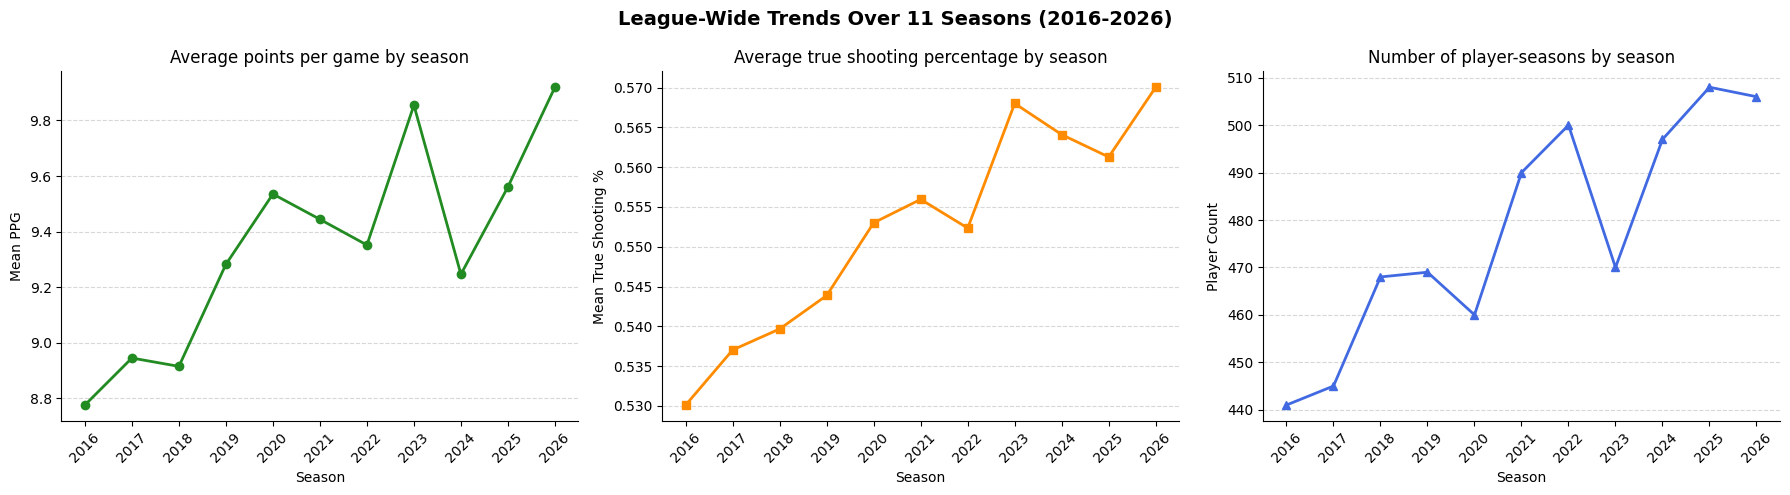

/tmp/ipykernel_2845/3755236698.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(eda_ppg_data, labels=eda_seasons)


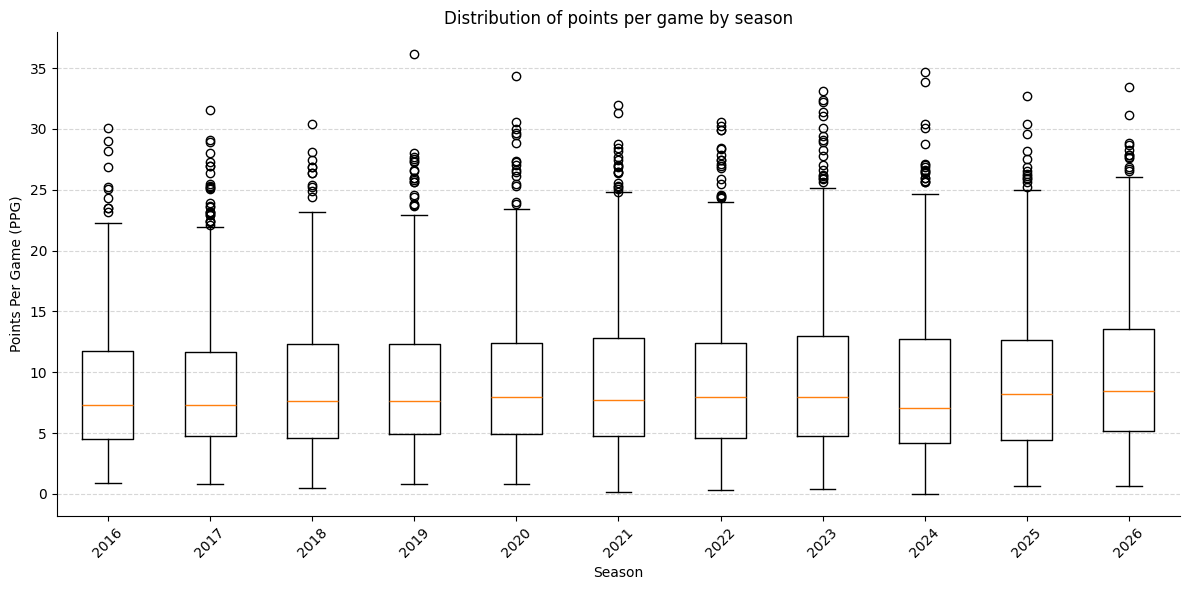

In [8]:
# Line charts by season
eda_season_trends = eda.groupby('season').agg(
    mean_ppg=('ppg', 'mean'),
    mean_ts_pct=('ts_pct', 'mean'),
    row_count=('player_id', 'count')
).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mean PPG
axes[0].plot(eda_season_trends.index, eda_season_trends['mean_ppg'], marker='o', color='forestgreen', linewidth=2)
axes[0].set_title('Average points per game by season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Mean PPG')

# Mean True Shooting
axes[1].plot(eda_season_trends.index, eda_season_trends['mean_ts_pct'], marker='s', color='darkorange', linewidth=2)
axes[1].set_title('Average true shooting percentage by season')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Mean True Shooting %')

# Number of Players
axes[2].plot(eda_season_trends.index, eda_season_trends['row_count'], marker='^', color='royalblue', linewidth=2)
axes[2].set_title('Number of player-seasons by season')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Player Count')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_xticks(eda_season_trends.index)
    ax.set_xticklabels([str(x) for x in eda_season_trends.index], rotation=45)

plt.suptitle('League-Wide Trends Over 11 Seasons (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Boxplot of ppg by season
fig, ax = plt.subplots(figsize=(12, 6))
eda_seasons = sorted(eda['season'].unique())
eda_ppg_data = [eda[eda['season'] == s]['ppg'] for s in eda_seasons]

ax.boxplot(eda_ppg_data, labels=eda_seasons)
ax.set_title('Distribution of points per game by season')
ax.set_xlabel('Season')
ax.set_ylabel('Points Per Game (PPG)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Shooting efficiency:** Average `ts_pct` goes from 53.0% in 2016 to 57.0% in 2026. The rise is not smooth (it dips in 2022, 2024 and 2025), but the overall direction is up.
* **Scoring:** Average `ppg` goes from 8.8 in 2016 to 9.9 in 2026, so it also drifts up a little.
* **Player-seasons per season:** The count (players with 10+ games) is lowest in 2016 (441), highest in 2025 (508), and 506 in 2026.

### 6F. The 3-year trend columns

We restrict our dataset to player-seasons that have a full 3-year window and are not suspicious to evaluate how current stats relate to past averages.

Number of records with valid 3-year trends: 3575


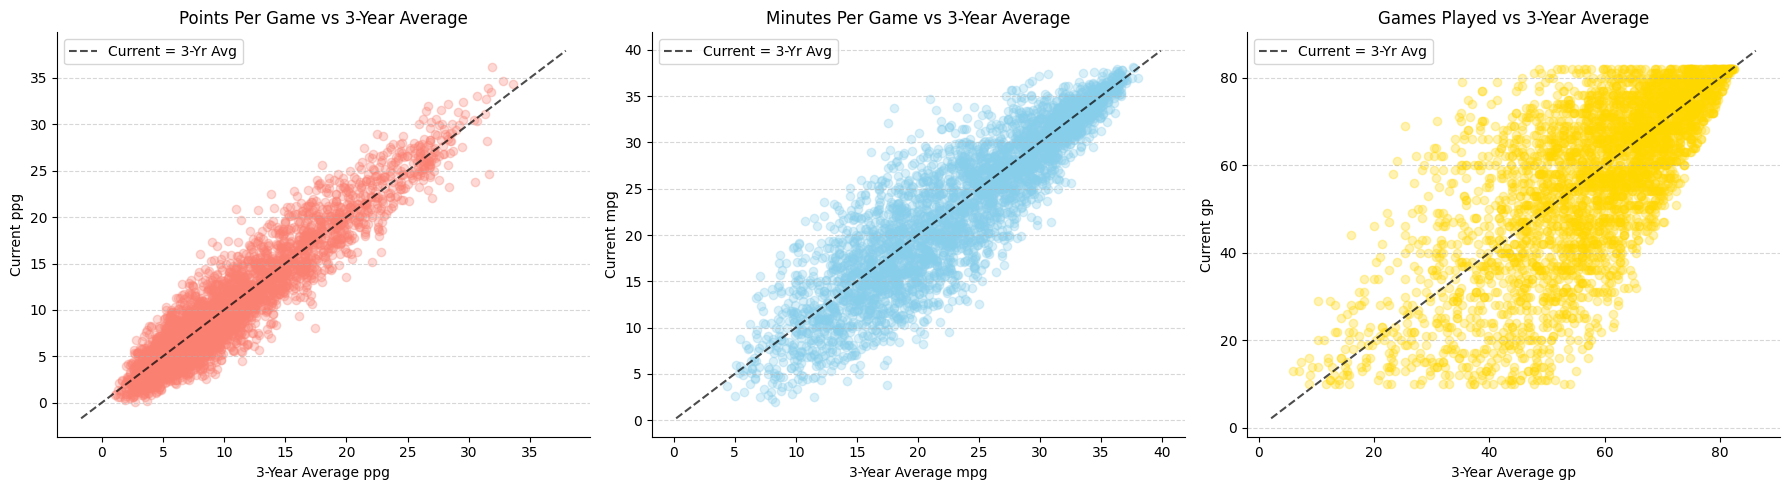


--- Summary Stats for PPG & GP Changes ---


,eda_ppg_change,eda_gp_change
count,3575.000,3575.000
mean,-0.090,-1.310
std,2.232,13.068
min,-9.320,-44.000
25%,-1.580,-9.000
50%,-0.220,-0.330
75%,1.305,6.670
max,9.850,43.670


Players scoring at least 3 PPG above their 3-yr average: 317
Players scoring at least 3 PPG below their 3-yr average: 281

--- Share of Missing Trends (%) by Experience Group ---


,missing_trend
exp_bin,
1 (Rookie),100.00
2,100.00
3,8.85
4-5,7.09
6-9,5.56
10+,3.79


In [9]:
# Subset data
eda_trend = eda[(eda['full_3yr_window'] == True) & (eda['suspicious_entry'] == False)].copy()
print(f"Number of records with valid 3-year trends: {len(eda_trend)}")

# 1. Scatter plots comparing current values to 3-year averages
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [('ppg', 'trend_3yr_ppg', 'Points Per Game', 'salmon'),
           ('mpg', 'trend_3yr_mpg', 'Minutes Per Game', 'skyblue'),
           ('gp', 'trend_3yr_gp', 'Games Played', 'gold')]

for i, (col, trend_col, name, color) in enumerate(metrics):
    axes[i].scatter(eda_trend[trend_col], eda_trend[col], alpha=0.3, color=color)
    # Add y = x line
    lims = [
        np.min([axes[i].get_xlim(), axes[i].get_ylim()]),
        np.max([axes[i].get_xlim(), axes[i].get_ylim()])
    ]
    axes[i].plot(lims, lims, 'k--', alpha=0.7, label='Current = 3-Yr Avg')
    axes[i].set_title(f'{name} vs 3-Year Average')
    axes[i].set_xlabel(f'3-Year Average {col}')
    axes[i].set_ylabel(f'Current {col}')
    axes[i].legend()
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Change distributions
eda_trend['eda_ppg_change'] = eda_trend['ppg'] - eda_trend['trend_3yr_ppg']
eda_trend['eda_gp_change'] = eda_trend['gp'] - eda_trend['trend_3yr_gp']

print("\n--- Summary Stats for PPG & GP Changes ---")
display(eda_trend[['eda_ppg_change', 'eda_gp_change']].describe().round(3))

# Count players with significant changes
ppg_up_3 = (eda_trend['eda_ppg_change'] >= 3).sum()
ppg_down_3 = (eda_trend['eda_ppg_change'] <= -3).sum()
print(f"Players scoring at least 3 PPG above their 3-yr average: {ppg_up_3}")
print(f"Players scoring at least 3 PPG below their 3-yr average: {ppg_down_3}")

# 3. Who is missing a trend?
eda['missing_trend'] = eda['full_3yr_window'] == False

def experience_bins(y):
    if y == 1:
        return '1 (Rookie)'
    elif y == 2:
        return '2'
    elif y == 3:
        return '3'
    elif y <= 5:
        return '4-5'
    elif y <= 9:
        return '6-9'
    else:
        return '10+'

eda['exp_bin'] = eda['years_in_nba'].apply(experience_bins)
missing_trend_share = eda.groupby('exp_bin')['missing_trend'].mean() * 100
print("\n--- Share of Missing Trends (%) by Experience Group ---")
display(missing_trend_share.reindex(['1 (Rookie)', '2', '3', '4-5', '6-9', '10+']).round(2))

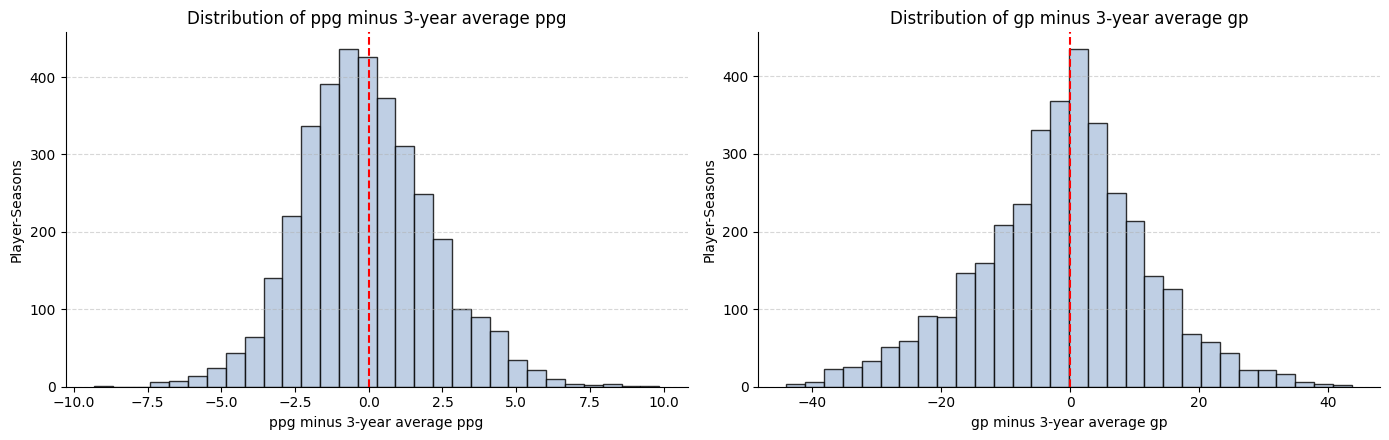

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, name in zip(axes, ['eda_ppg_change', 'eda_gp_change'],
                         ['ppg minus 3-year average ppg', 'gp minus 3-year average gp']):
    ax.hist(eda_trend[col], bins=30, color='lightsteelblue', edgecolor='black', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--')
    ax.set_title(f'Distribution of {name}')
    ax.set_xlabel(name)
    ax.set_ylabel('Player-Seasons')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### What we found

* **Current stats stay close to the 3-year average:** Across 3,575 player-seasons, the average difference between `ppg` and the 3-year average is -0.09, and the middle half is between -1.58 and +1.31.
* **Bigger changes exist:** 317 player-seasons are at least 3 `ppg` above the 3-year average, and 281 are at least 3 below. The change in games played is wider (standard deviation 13 games).
* **Missing trend:** 100% of rookies and second-year players have no 3-year trend (27.6% of all rows). For other groups it is 8.8% (3rd year), 7.1% (4-5), 5.6% (6-9) and 3.8% (10+), caused by missed seasons. A model that uses trend columns must handle this.

### 6G. Players who stay vs players who appear and disappear

We analyze player longevity by counting how many seasons each player appears in the regular season dataset, comparing short-career players against veterans.

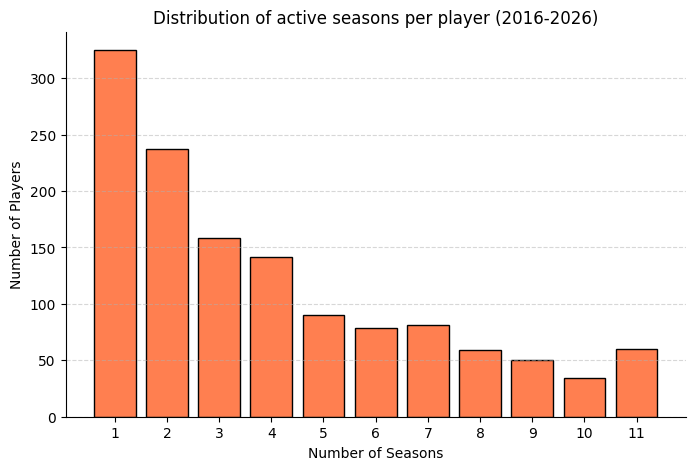

Share of total player-seasons belonging to players with only 1-2 seasons: 15.21%


,ppg,mpg,age,years_in_nba
career_length_group,,,,
Short-career (1-2 seasons),4.18,12.48,24.0,2.0
Long-career (6+ seasons),10.21,25.41,27.0,6.0


In [11]:
# 1. Count seasons per player
player_season_counts = eda.groupby('player_name')['season'].count()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(player_season_counts, bins=range(1, 13), align='left', color='coral', edgecolor='black', rwidth=0.8)
ax.set_title('Distribution of active seasons per player (2016-2026)')
ax.set_xlabel('Number of Seasons')
ax.set_ylabel('Number of Players')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_xticks(range(1, 12))
plt.show()

# 2. Share of player-seasons belonging to 1-2 season players
short_career_players = player_season_counts[player_season_counts <= 2].index
short_career_share = eda['player_name'].isin(short_career_players).mean() * 100
print(f"Share of total player-seasons belonging to players with only 1-2 seasons: {short_career_share:.2f}%")

# 3. Compare statistics
eda['career_length_group'] = eda['player_name'].apply(
    lambda x: 'Short-career (1-2 seasons)' if player_season_counts[x] <= 2
    else ('Long-career (6+ seasons)' if player_season_counts[x] >= 6 else 'Medium-career')
)

career_comparison = eda.groupby('career_length_group')[['ppg', 'mpg', 'age', 'years_in_nba']].median()
display(career_comparison.reindex(['Short-career (1-2 seasons)', 'Long-career (6+ seasons)']))

### What we found

* **Short careers in the table:** 562 of 1,315 players (43%) appear in only 1-2 seasons, and they make up 15.2% of all player-seasons.
* **Difference:** Players with 6+ seasons have median 10.2 `ppg` and 25.4 `mpg`, compared with 4.2 `ppg` and 12.5 `mpg` for players with 1-2 seasons. The short group also has a median age of 24 vs 27.
* **Be careful:** This counts seasons only inside 2016-2026 (and only seasons with 10+ games). A player who debuted in 2025 or retired in 2017 looks "short" even if his career was long. So this is not proof that weaker players have shorter careers.

### 6H. Summary of the EDA

Based on our comprehensive exploratory data analysis of the regular season dataset, we summarize key findings:

* **Highly Variable Metrics:** Stats related to on-court production like `ppg`, `rpg`, `apg`, and `bpg` are highly variable and strongly right-skewed, showing that elite performers reside in a thin tail.
* **High Collinearity:** Key variables like `mpg` and `ppg` have an extremely high correlation (0.875). Age and experience also display near-perfect linearity (0.91). A trade-prediction model will likely not need both variables to avoid collinearity issues.
* **The Missing Trend Challenge:** 3-year rolling trend values are absent for 100% of rookies and second-year players, who make up 27.6% of the rows. Models using trend features will face missing-data issues for young players.
* **Estimated years in the NBA:** 19.1% of rows have an estimated `years_in_nba`, so this variable carries some error. We should keep `years_in_nba_estimated` as a flag, or test models with and without it.
* **Next Steps for Modeling:**
  1. How do we impute or handle missing 3-year trends for young players without discarding them from trade models?
  2. Since performance levels are highly stable from year to year, does a sudden drop or rise in stats relative to a player's 3-year average act as a trigger for getting traded?
  3. Should we normalize right-skewed stats (e.g. log transformations) before feeding them into our classification models?